# 01. Data Cleaning & Preprocessing
**UPI Fraud Detection and Risk Analytics**

### Objectives:
1. Load and inspect the raw UPI transactions dataset (`UPI_Transactions_Raw.csv`).
2. Perform comprehensive data audit (missing values, data types, value distributions).
3. Handle missing values cleanly (`Failure_Reason` for non-failed transactions).
4. Parse date fields into structured temporal features (`Transaction_Date`, `Year`, `Month`, `Day_of_Week`, `Quarter`, `Is_Weekend`).
5. Conduct outlier analysis on numerical fields (`Amount`, `Processing_Time_sec`, `Bank_Response_Time_ms`).
6. Validate data integrity (duplicate `Transaction_ID` check, constraint checks).
7. Save the processed dataset to `data/processed/UPI_Transactions_Cleaned.csv`.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display configurations
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_style('whitegrid')
%matplotlib inline

print('Pandas version:', pd.__version__)
print('Numpy version:', np.__version__)


Pandas version: 3.0.3
Numpy version: 2.5.0


## 1. Load Raw Dataset

In [4]:
raw_path = r"C:\UPI Data\UPI_Transactions_Raw.csv"
if not os.path.exists(raw_path):
    raw_path = r"C:\UPI Data\UPI_Transactions_Raw.csv"

df = pd.read_csv(raw_path)
print(f'Raw Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
print('\nDataset Info:')
df.info()


Raw Dataset Shape: 10000 rows, 16 columns

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transaction_ID         10000 non-null  str    
 1   Transaction_Date       10000 non-null  str    
 2   Customer_ID            10000 non-null  str    
 3   City                   10000 non-null  str    
 4   State                  10000 non-null  str    
 5   Sender_Bank            10000 non-null  str    
 6   Receiver_Bank          10000 non-null  str    
 7   UPI_App                10000 non-null  str    
 8   Transaction_Type       10000 non-null  str    
 9   Payment_Method         10000 non-null  str    
 10  Amount                 10000 non-null  float64
 11  Transaction_Status     10000 non-null  str    
 12  Failure_Reason         707 non-null    str    
 13  Processing_Time_sec    10000 non-null  float64
 14  Bank_Resp

In [5]:
print('First 5 rows of Raw Data:')
df.head()


First 5 rows of Raw Data:


,Transaction_ID,Transaction_Date,Customer_ID,City,State,Sender_Bank,Receiver_Bank,UPI_App,Transaction_Type,Payment_Method,Amount,Transaction_Status,Failure_Reason,Processing_Time_sec,Bank_Response_Time_ms,Fraud_Label
0,TXN100000,2025-11-24,CUST09196,Bengaluru,Karnataka,SBI,Kotak Mahindra Bank,PhonePe,Online Purchase,Mobile Number,2014.53,Success,NaN,4.83,801,0
1,TXN100001,2025-04-23,CUST01520,Ahmedabad,Gujarat,Yes Bank,Kotak Mahindra Bank,BHIM,P2P,UPI ID,1359.97,Success,NaN,1.58,751,0
2,TXN100002,2025-06-26,CUST09460,Lucknow,Uttar Pradesh,Kotak Mahindra Bank,SBI,PhonePe,P2P,UPI,8199.06,Success,NaN,3.03,816,0
3,TXN100003,2025-12-05,CUST05821,Mumbai,Maharashtra,Kotak Mahindra Bank,HDFC Bank,PhonePe,Bill Payment,UPI,2240.06,Success,NaN,3.58,345,0
4,TXN100004,2025-11-08,CUST00526,Kochi,Kerala,ICICI Bank,Union Bank,Paytm,Recharge,UPI ID,320.36,Success,NaN,4.48,888,0


## 2. Missing Value & Data Type Audit

In [6]:
null_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100,
    'Data_Type': df.dtypes
})
print(null_summary[null_summary['Missing_Count'] > 0])


                Missing_Count  Missing_Percentage Data_Type
Failure_Reason           9293               92.93       str


In [7]:
print('Breakdown of Failure_Reason by Transaction_Status:')
pd.crosstab(df['Transaction_Status'], df['Failure_Reason'].fillna('Missing'), dropna=False)


Breakdown of Failure_Reason by Transaction_Status:


Failure_Reason,Bank Server Error,Daily Limit Exceeded,Insufficient Balance,Invalid UPI PIN,Missing,Network Error,Transaction Timeout
Transaction_Status,,,,,,,
Failed,123,121,128,116,0,104,115
Pending,0,0,0,0,146,0,0
Success,0,0,0,0,9147,0,0


## 3. Data Cleaning & Imputation

In [8]:
# Fill Failure_Reason for non-failed transactions with 'Not Applicable'
df_clean = df.copy()
df_clean['Failure_Reason'] = df_clean['Failure_Reason'].fillna('Not Applicable')

print('Post-Imputation Missing Values Check:')
print(df_clean.isnull().sum())


Post-Imputation Missing Values Check:
Transaction_ID           0
Transaction_Date         0
Customer_ID              0
City                     0
State                    0
Sender_Bank              0
Receiver_Bank            0
UPI_App                  0
Transaction_Type         0
Payment_Method           0
Amount                   0
Transaction_Status       0
Failure_Reason           0
Processing_Time_sec      0
Bank_Response_Time_ms    0
Fraud_Label              0
dtype: int64


## 4. Date Parsing & Temporal Feature Engineering

In [9]:
df_clean['Transaction_Date'] = pd.to_datetime(df_clean['Transaction_Date'])
df_clean['Year'] = df_clean['Transaction_Date'].dt.year
df_clean['Month'] = df_clean['Transaction_Date'].dt.month
df_clean['Month_Name'] = df_clean['Transaction_Date'].dt.strftime('%b')
df_clean['Day'] = df_clean['Transaction_Date'].dt.day
df_clean['Day_of_Week'] = df_clean['Transaction_Date'].dt.day_name()
df_clean['Day_of_Week_Num'] = df_clean['Transaction_Date'].dt.dayofweek
df_clean['Is_Weekend'] = df_clean['Day_of_Week_Num'].apply(lambda x: 1 if x >= 5 else 0)
df_clean['Quarter'] = df_clean['Transaction_Date'].dt.quarter

min_date = df_clean['Transaction_Date'].min().strftime('%Y-%m-%d')
max_date = df_clean['Transaction_Date'].max().strftime('%Y-%m-%d')
print(f'Date Range: {min_date} to {max_date}')
df_clean[['Transaction_Date', 'Month_Name', 'Day_of_Week', 'Is_Weekend', 'Quarter']].head()


Date Range: 2025-01-01 to 2025-12-31


,Transaction_Date,Month_Name,Day_of_Week,Is_Weekend,Quarter
0,2025-11-24,Nov,Monday,0,4
1,2025-04-23,Apr,Wednesday,0,2
2,2025-06-26,Jun,Thursday,0,2
3,2025-12-05,Dec,Friday,0,4
4,2025-11-08,Nov,Saturday,1,4


## 5. Outlier Analysis & Boundary Validation

In [10]:
num_cols = ['Amount', 'Processing_Time_sec', 'Bank_Response_Time_ms']
outlier_stats = []

for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    outlier_stats.append({
        'Feature': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower_Bound': round(lower_bound, 2),
        'Upper_Bound': round(upper_bound, 2),
        'Outlier_Count': len(outliers),
        'Outlier_Pct': round((len(outliers) / len(df_clean)) * 100, 2)
    })

pd.DataFrame(outlier_stats)


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Pct
0,Amount,414.14,1598.16,1184.02,-1361.88,3374.19,767,7.67
1,Processing_Time_sec,2.02,5.30,3.28,-2.90,10.22,316,3.16
2,Bank_Response_Time_ms,483.00,819.00,336.00,-21.00,1323.00,42,0.42


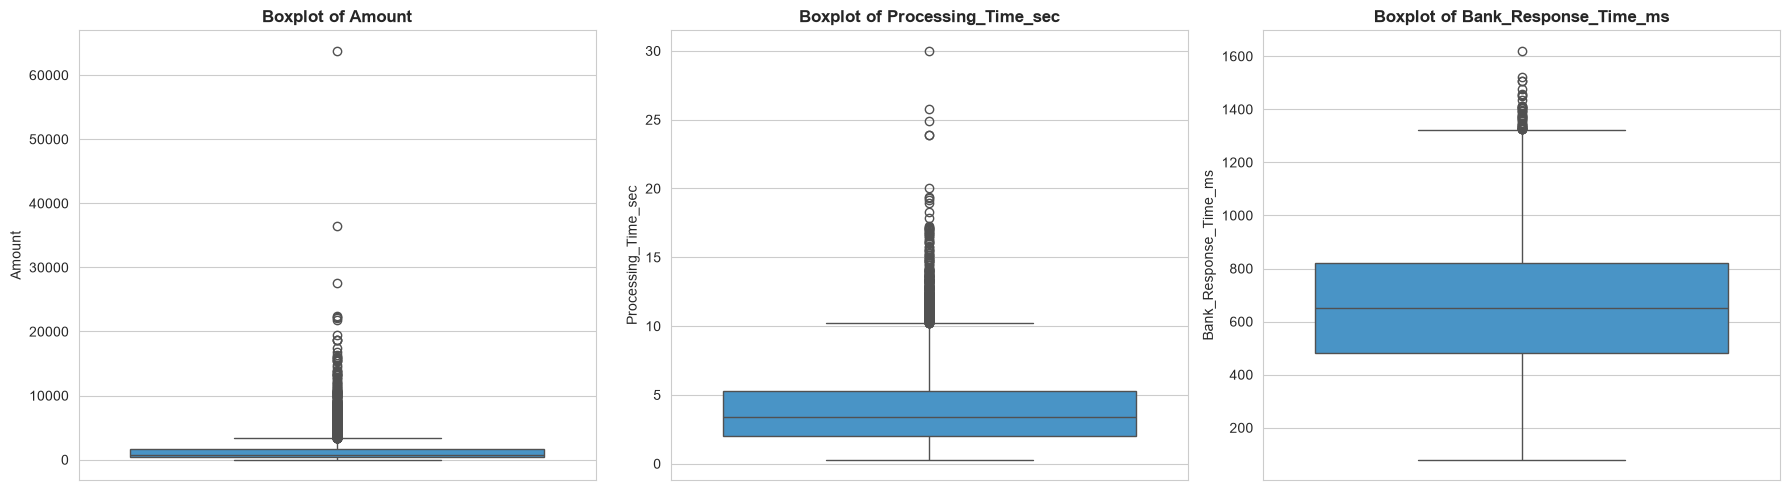

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df_clean[col], ax=axes[i], color='#3498db')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Duplicate & Constraint Checks

In [12]:
duplicate_ids = df_clean['Transaction_ID'].duplicated().sum()
duplicate_rows = df_clean.duplicated().sum()
print(f'Duplicate Transaction IDs: {duplicate_ids}')
print(f'Duplicate Full Rows: {duplicate_rows}')

print('\nUnique Customers Count:', df_clean['Customer_ID'].nunique())
print('\nFraud Label Distribution:')
print(df_clean['Fraud_Label'].value_counts())


Duplicate Transaction IDs: 0
Duplicate Full Rows: 0

Unique Customers Count: 7228

Fraud Label Distribution:
Fraud_Label
0    9901
1      99
Name: count, dtype: int64


## 7. Save Cleaned Dataset

In [17]:
import os
import pandas as pd

# Path to your cleaned dataset
out_path = r"C:\UPI Data\UPI_Transactions_Cleaned.csv"

# Save the cleaned dataset
df_clean.to_csv(out_path, index=False)

# Verify the saved file
df_check = pd.read_csv(out_path)

print("Saved successfully!")
print("Location:", out_path)
print("Shape:", df_check.shape)
print("\nFirst 5 rows:")
display(df_check.head())

Saved successfully!
Location: C:\UPI Data\UPI_Transactions_Cleaned.csv
Shape: (10000, 24)

First 5 rows:


,Transaction_ID,Transaction_Date,Customer_ID,City,State,Sender_Bank,Receiver_Bank,UPI_App,Transaction_Type,Payment_Method,Amount,Transaction_Status,Failure_Reason,Processing_Time_sec,Bank_Response_Time_ms,Fraud_Label,Year,Month,Month_Name,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend,Quarter
0,TXN100000,2025-11-24,CUST09196,Bengaluru,Karnataka,SBI,Kotak Mahindra Bank,PhonePe,Online Purchase,Mobile Number,2014.53,Success,Not Applicable,4.83,801,0,2025,11,Nov,24,Monday,0,0,4
1,TXN100001,2025-04-23,CUST01520,Ahmedabad,Gujarat,Yes Bank,Kotak Mahindra Bank,BHIM,P2P,UPI ID,1359.97,Success,Not Applicable,1.58,751,0,2025,4,Apr,23,Wednesday,2,0,2
2,TXN100002,2025-06-26,CUST09460,Lucknow,Uttar Pradesh,Kotak Mahindra Bank,SBI,PhonePe,P2P,UPI,8199.06,Success,Not Applicable,3.03,816,0,2025,6,Jun,26,Thursday,3,0,2
3,TXN100003,2025-12-05,CUST05821,Mumbai,Maharashtra,Kotak Mahindra Bank,HDFC Bank,PhonePe,Bill Payment,UPI,2240.06,Success,Not Applicable,3.58,345,0,2025,12,Dec,5,Friday,4,0,4
4,TXN100004,2025-11-08,CUST00526,Kochi,Kerala,ICICI Bank,Union Bank,Paytm,Recharge,UPI ID,320.36,Success,Not Applicable,4.48,888,0,2025,11,Nov,8,Saturday,5,1,4
